SUITE P9 - ANALYSES STATISTIQUES

In [1]:
#Imports + Chargement + Nettoyage

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, f_oneway, ttest_ind, pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# Options d'affichage
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# Chargement des datasets
df_customers = pd.read_csv("../Data/customers.csv", sep=';')
df_products = pd.read_csv("../Data/products.csv", sep=';')
df_transactions = pd.read_csv("../Data/Transactions.csv", sep=';', engine='python')

#Suppression des lignes vides dans le dataset transactions
df_transactions.dropna(inplace=True)

#Merge pour reconstruire le dataset final
df = df_transactions.merge(df_products, on="id_prod", how="left")
df_final = df.merge(df_customers, on="client_id", how="left")

# Exclure les quatre comptes BtoB avant toute analyse par âge ou genre.
liste_b2b = ["c_1609", "c_4958", "c_6714", "c_3454"]
df_final = df_final.loc[~df_final["client_id"].isin(liste_b2b)].copy()

# Calcul de l'âge à partir de l'année de naissance.
df_final["age"] = 2022 - df_final["birth"]

# Création de la tranche d'âge sur les seuls clients BtoC.
bins = [0, 19, 29, 39, 49, 59, 69, 200]
labels = ["0-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70+"]
df_final["age_group"] = pd.cut(df_final["age"], bins=bins, labels=labels, right=True)

#Renommage de session_id en freq_achats
df_final.rename(columns={"session_id": "freq_achats"}, inplace=True)

# Les tests statistiques utilisent également ce périmètre BtoC.
df_stats = df_final.copy()

# Vérification rapide
df_final.head()


,id_prod,date,freq_achats,client_id,price,categ,sex,birth,age,age_group
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,11.99,0,f,1967,55,50-59
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,19.37,0,m,1960,62,60-69
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,4.50,0,m,1988,34,30-39
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912,6.55,0,f,1989,33,30-39
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033,16.49,0,f,1956,66,60-69


#Test du χ² : Tranche d’âge × Catégorie

#H0 : la catégorie achetée est indépendante de la tranche d’âge
#H1 : la catégorie achetée dépend de la tranche d’âge

In [2]:
#Table de contingence
ct = pd.crosstab(df_stats["age_group"], df_stats["categ"])
ct


categ,0,1,2
age_group,,,
0-19,4327,7865,7796
20-29,11119,19765,19735
30-39,135156,45009,2990
40-49,153457,49843,769
50-59,43899,46666,718
60-69,24549,31774,539
70+,14774,19683,301


In [3]:
# Test du χ²
chi2, p, dof, expected = chi2_contingency(ct)

print("Chi² :", chi2)
print("p-value :", p)
print("Degrés de liberté :", dof)
print("\nFréquences attendues :\n", expected)


Chi² : 246417.72058467587
p-value : 0.0
Degrés de liberté : 12

Fréquences attendues :
 [[ 12081.41385973   6881.87725328   1024.708887  ]
 [ 30595.81189542  17428.14412065   2595.04398393]
 [110704.9907684   63060.34762476   9389.66160684]
 [123346.10991301  70261.04708818  10461.84299881]
 [ 55174.48976174  31428.77733193   4679.73290632]
 [ 34369.28931819  19577.61178586   2915.09889595]
 [ 21008.89448351  11967.19479534   1781.91072114]]


Le test du χ² montre une association entre tranche d'âge et catégorie achetée dans les lignes de vente analysées. Les achats répétés d'un même client ne sont toutefois pas indépendants ; la p-value calculée sur chaque ligne ne doit pas être interprétée comme une preuve causale ou comme un test au niveau des personnes.


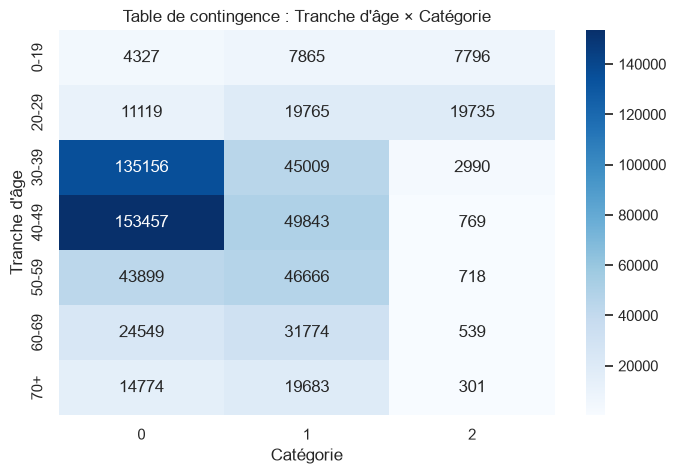

In [4]:
# Visualisation de la table de contingence avec un heatmap
plt.figure(figsize=(8,5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Table de contingence : Tranche d'âge × Catégorie")
plt.xlabel("Catégorie")
plt.ylabel("Tranche d'âge")
plt.show()


TEST ANOVA - PANIER MOYEN x TRANCHE D'AGE

In [5]:
# Création de client_panier : agrégation par client
# Utiliser 'price' pour la somme des ventes et 'freq_achats' pour le nombre de sessions
client_panier = (df_final.groupby("client_id").agg({"price": "sum", "freq_achats": "nunique", "age_group": "first"}).reset_index())
client_panier.rename(columns={"price": "ca"}, inplace=True)
client_panier["panier_moyen"] = (client_panier["ca"] / client_panier["freq_achats"]).round(2)

# Vérification
client_panier.head()

,client_id,ca,freq_achats,age_group,panier_moyen
0,c_1,629.02,34,60-69,18.50
1,c_10,1353.60,34,60-69,39.81
2,c_100,254.85,5,30-39,50.97
3,c_1000,2291.88,94,50-59,24.38
4,c_1001,1823.85,47,40-49,38.81


In [6]:
#On crée les groupes pour chaque tranche d'âge
groups = []
for g in client_panier["age_group"].dropna().unique():
    groups.append(client_panier.loc[client_panier["age_group"] == g, "panier_moyen"])

#ANOVA
f_stat, p_val = f_oneway(*groups)

print("Statistique F :", f_stat)
print("p-value :", p_val)


Statistique F : 1780.8142826696444
p-value : 0.0


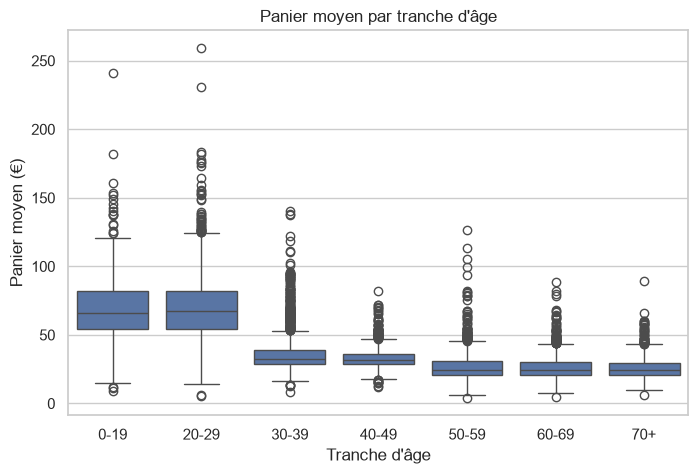

In [7]:
# Visualisation du panier moyen par tranche d'âge
plt.figure(figsize=(8,5))
sns.boxplot(data=client_panier, x="age_group", y="panier_moyen")
plt.title("Panier moyen par tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Panier moyen (€)")
plt.show()


Le panier moyen par session diffère selon les tranches d'âge dans cet échantillon. L'ANOVA détecte une différence statistique, sans expliquer les motivations d'achat ni établir que l'âge en est la cause.


TEST X² : GENRE x CATEGORIE

In [8]:
#Table de contingence Genre x Catégorie
ct_genre_categ = pd.crosstab(df_final["sex"], df_final["categ"])

#Test du chi²
chi2, p_value, dof, expected = chi2_contingency(ct_genre_categ)

print("Chi² :", round(chi2, 4))
print("p-value :", p_value)
print("Degrés de liberté :", dof)

Chi² : 22.6686
p-value : 1.1955928116587024e-05
Degrés de liberté : 2


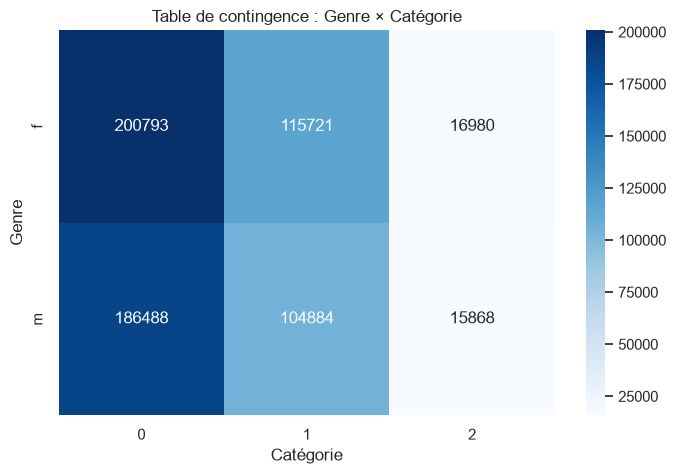

In [9]:
#  pour visualiser
plt.figure(figsize=(8,5))
sns.heatmap(ct_genre_categ, annot=True, fmt="d", cmap="Blues")
plt.title("Table de contingence : Genre × Catégorie")
plt.xlabel("Catégorie")
plt.ylabel("Genre")
plt.show()

Le test du χ² détecte une association entre genre et catégorie achetée sur ces lignes de vente, mais l'effet est très faible au regard du volume de données. Les achats répétés par une même personne limitent aussi l'interprétation de la p-value.


TEST DE SPEARMAN : ÂGE × MONTANT TOTAL DES ACHATS PAR CLIENT


In [10]:
# Une observation par client particulier ; l'âge est traité comme variable numérique.
montant = (
    df_final.groupby("client_id")
    .agg(montant_total=("price", "sum"), age=("age", "first"), age_group=("age_group", "first"))
    .dropna(subset=["age"])
    .reset_index()
)
rho_montant, p_montant = spearmanr(montant["age"], montant["montant_total"])
print("Spearman ρ :", round(rho_montant, 4))
print("p-value :", p_montant)


Spearman ρ : -0.1845
p-value : 1.0212910436382563e-66


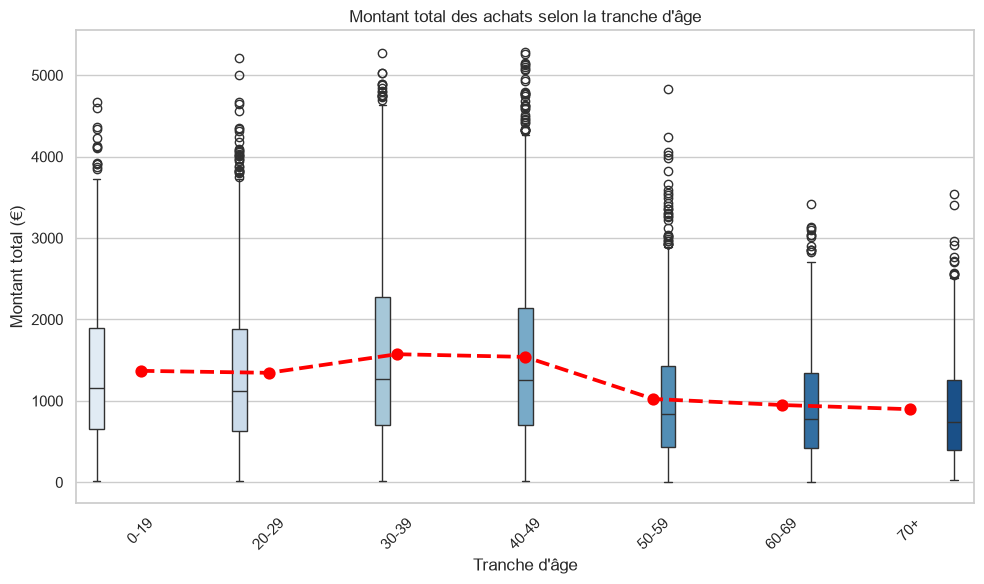

In [11]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=montant,
    x="age_group",
    y="montant_total",
    hue="age_group",
    palette="Blues",
    legend=False
)

sns.pointplot(
    data=montant,
    x="age_group",
    y="montant_total",
    estimator=np.mean,
    color="red",
    markers="o",
    linestyles="--",
    errorbar=None
)

plt.title("Montant total des achats selon la tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Montant total (€)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Le coefficient de Spearman montre une relation négative faible entre l'âge et le montant total dépensé par client particulier. Le graphique par tranche d'âge décrit les distributions ; il n'établit pas une baisse régulière pour chaque âge ni un effet causal.


TEST DE SPEARMAN : ÂGE × FRÉQUENCE D'ACHAT PAR CLIENT


In [12]:
# Nombre de sessions distinctes par client particulier.
freq_achat = (
    df_final.groupby("client_id")
    .agg(freq_achats=("freq_achats", "nunique"), age=("age", "first"), age_group=("age_group", "first"))
    .dropna(subset=["age"])
    .reset_index()
)
rho_freq, p_freq = spearmanr(freq_achat["age"], freq_achat["freq_achats"])
print("Spearman ρ :", round(rho_freq, 4))
print("p-value :", p_freq)


Spearman ρ : 0.212
p-value : 6.629168433162731e-88


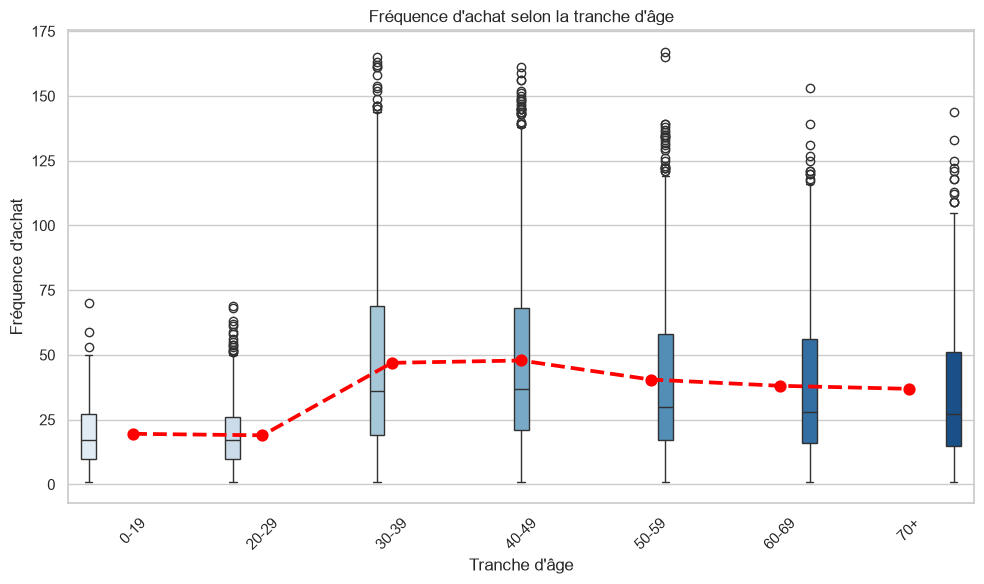

In [13]:
#Visualisation de la fréquence d'achat par tranche d'âge
plt.figure(figsize=(10,6))

sns.boxplot(
    data=freq_achat,
    x="age_group",
    y="freq_achats",
    hue="age_group",
    palette="Blues",
    legend=False
)

sns.pointplot(
    data=freq_achat,
    x="age_group",
    y="freq_achats",
    estimator=np.mean,
    color="red",
    markers="o",
    linestyles="--",
    errorbar=None
)

plt.title("Fréquence d'achat selon la tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Fréquence d'achat")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Le coefficient de Spearman montre une relation positive faible entre l'âge et le nombre de sessions par client particulier. La relation n'est pas monotone dans les médianes par tranche : la fréquence est surtout élevée chez les 30–49 ans. Elle ne permet pas d'attribuer les achats à l'âge seul.
